In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Folder containing your exported EDA tables
table_dir = Path(
    r"C:\Users\LATO\Documents\Sales Analysis\Analysis Tables"
)

# All exported analysis table names
table_names = [
    "order_analysis",
    "order_revenue",
    "sales_data",
    "monthly_aov",
    "status_analysis",
    "product_analysis",
    "product_sales",
    "customer_analysis",
    "customer_orders",
    "customer_order_counts",
    "customer_spending",
    "customer_geography",
    "seller_analysis",
    "seller_performance",
    "top_sellers",
    "top_revenue_sellers",
    "payment_methods",
    "payment_value_analysis",
    "installment_analysis",
    "delivery_data",
    "delivered_orders",
    "delivery_status_summary",
    "delivery_by_state",
    "review_data",
    "review_distribution",
    "order_reviews",
    "category_review_summary",
    "delivery_review_summary",
    "customers_by_state",
    "sellers_by_state",
    "revenue_by_state",
    "customer_seller_comparison"
]

# Load every table that exists
loaded_tables = {}
missing_tables = []

for name in table_names:
    file_path = table_dir / f"{name}.csv"

    if file_path.exists():
        loaded_tables[name] = pd.read_csv(file_path)
    else:
        missing_tables.append(name)

# Create a separate variable for each loaded table
globals().update(loaded_tables)

print(f"Successfully loaded: {len(loaded_tables)} tables")

if missing_tables:
    print("\nFiles not found:")
    for name in missing_tables:
        print(f"- {name}.csv")
else:
    print("All listed tables were found.")

Successfully loaded: 32 tables
All listed tables were found.


In [2]:
orders = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_orders_dataset.csv")

customers = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_customers_dataset.csv")

order_items = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_order_items_dataset.csv")

products = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_products_dataset.csv")

sellers = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_sellers_dataset.csv")

payments = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_order_payments_dataset.csv")

reviews = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_order_reviews_dataset.csv")

geolocation = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_geolocation_dataset.csv")

category_translation = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\product_category_name_translation.csv")

In [4]:
print("Order status counts:")
display(orders["order_status"].value_counts(dropna=False))

print("\nMissing purchase timestamps:")
print(orders["order_purchase_timestamp"].isna().sum())

print("\nMissing order IDs:")
print("Orders:", orders["order_id"].isna().sum())
print("Order items:", order_items["order_id"].isna().sum())

print("\nMissing item prices:")
print(order_items["price"].isna().sum())

print("\nDuplicate order-item rows:")
print(order_items.duplicated().sum())

Order status counts:


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


Missing purchase timestamps:
0

Missing order IDs:
Orders: 0
Order items: 0

Missing item prices:
0

Duplicate order-item rows:
0


In [5]:
# Keep the order information needed for sales analysis
orders_sales = orders[
    ["order_id", "order_purchase_timestamp", "order_status"]
].copy()

# Merge order details with item-level sales
sales_data = order_items.merge(
    orders_sales,
    on="order_id",
    how="left",
    validate="many_to_one"
)

print("Merged dataset shape:", sales_data.shape)
display(sales_data.head())

Merged dataset shape: (112650, 9)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,order_status
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,delivered
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,delivered
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,delivered
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,delivered
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,delivered


In [6]:
# Exclude canceled and unavailable orders
excluded_statuses = ["canceled", "unavailable"]

sales_data = sales_data[
    ~sales_data["order_status"].isin(excluded_statuses)
].copy()

print("Rows after filtering:", len(sales_data))
print("\nRemaining order statuses:")
display(sales_data["order_status"].value_counts())

Rows after filtering: 112101

Remaining order statuses:


order_status
delivered     110197
shipped         1185
invoiced         359
processing       357
approved           3
Name: count, dtype: int64

In [8]:
# Convert purchase timestamp to datetime
sales_data["order_purchase_timestamp"] = pd.to_datetime(
    sales_data["order_purchase_timestamp"],
    errors="coerce"
)

# Check the data type and missing values
print("Data type:", sales_data["order_purchase_timestamp"].dtype)
print("Missing timestamps:", sales_data["order_purchase_timestamp"].isna().sum())

Data type: datetime64[ns]
Missing timestamps: 0


In [9]:
# Create a monthly period
sales_data["sales_month"] = (
    sales_data["order_purchase_timestamp"].dt.to_period("M")
)

# Aggregate sales by month
monthly_sales = (
    sales_data.groupby("sales_month")
    .agg(
        monthly_revenue=("price", "sum"),
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count")
    )
    .reset_index()
)

# Convert monthly periods to timestamps
monthly_sales["sales_month"] = (
    monthly_sales["sales_month"].dt.to_timestamp()
)

display(monthly_sales.head(10))
display(monthly_sales.tail(10))

print("Number of months:", len(monthly_sales))
print("First month:", monthly_sales["sales_month"].min())
print("Last month:", monthly_sales["sales_month"].max())

,sales_month,monthly_revenue,orders,items_sold
0,2016-09-01,207.86,2,5
1,2016-10-01,44507.30,290,342
2,2016-12-01,10.90,1,1
3,2017-01-01,120098.27,787,953
4,2017-02-01,244959.35,1718,1936
5,2017-03-01,368341.32,2617,2975
6,2017-04-01,353842.98,2377,2660
7,2017-05-01,503159.19,3640,4106
8,2017-06-01,429916.61,3205,3571
9,2017-07-01,492287.30,3946,4493


,sales_month,monthly_revenue,orders,items_sold
14,2017-12-01,742183.79,5618,6300
15,2018-01-01,945456.29,7187,8173
16,2018-02-01,837895.43,6624,7597
17,2018-03-01,981051.06,7168,8195
18,2018-04-01,993592.98,6919,7957
19,2018-05-01,992871.75,6833,7898
20,2018-06-01,863265.53,6145,7060
21,2018-07-01,878044.27,6233,7039
22,2018-08-01,848860.10,6421,7216
23,2018-09-01,145.00,1,1


Number of months: 24
First month: 2016-09-01 00:00:00
Last month: 2018-09-01 00:00:00


In [10]:
# Create a continuous monthly index
monthly_index = pd.date_range(
    start=monthly_sales["sales_month"].min(),
    end=monthly_sales["sales_month"].max(),
    freq="MS"
)

monthly_sales = (
    monthly_sales.set_index("sales_month")
    .reindex(monthly_index)
    .rename_axis("sales_month")
    .reset_index()
)

# Fill missing monthly activity with zero
monthly_sales[["monthly_revenue", "orders", "items_sold"]] = (
    monthly_sales[["monthly_revenue", "orders", "items_sold"]]
    .fillna(0)
)

print("Total months after reindexing:", len(monthly_sales))
print("Months with zero revenue:", (monthly_sales["monthly_revenue"] == 0).sum())

display(monthly_sales.head())

Total months after reindexing: 25
Months with zero revenue: 1


,sales_month,monthly_revenue,orders,items_sold
0,2016-09-01,207.86,2.0,5.0
1,2016-10-01,44507.30,290.0,342.0
2,2016-11-01,0.00,0.0,0.0
3,2016-12-01,10.90,1.0,1.0
4,2017-01-01,120098.27,787.0,953.0


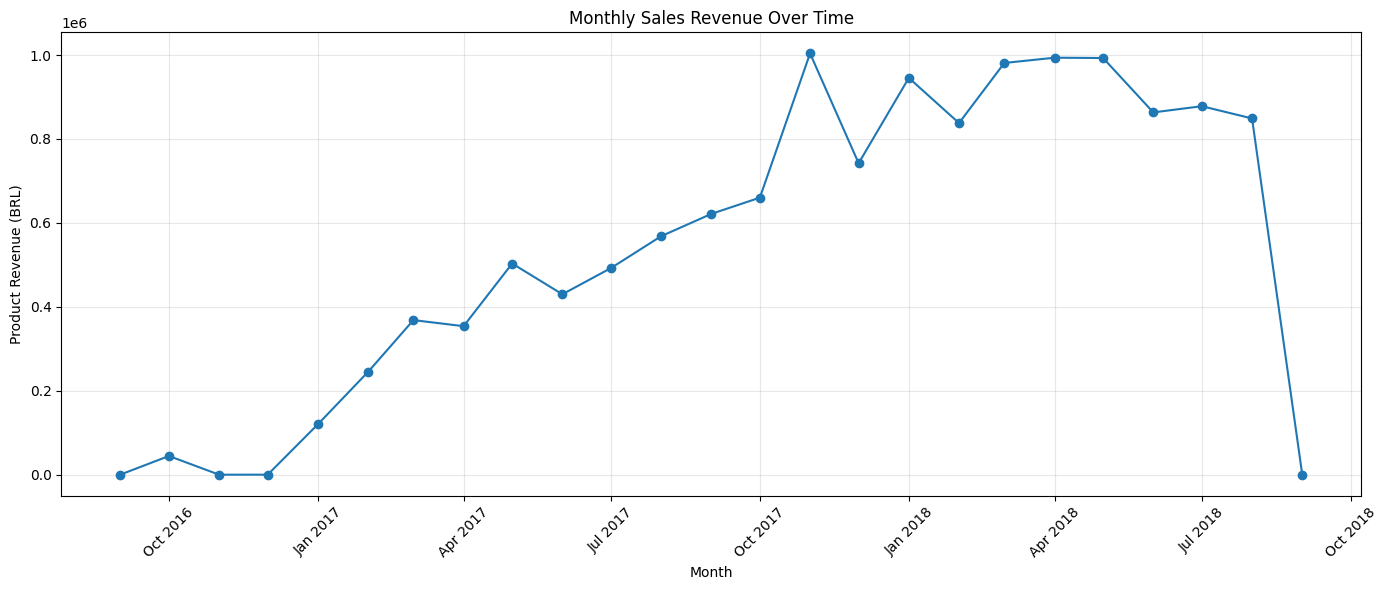

In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["sales_month"],
    monthly_sales["monthly_revenue"],
    marker="o"
)

plt.title("Monthly Sales Revenue Over Time")
plt.xlabel("Month")
plt.ylabel("Product Revenue (BRL)")
plt.xticks(rotation=45)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

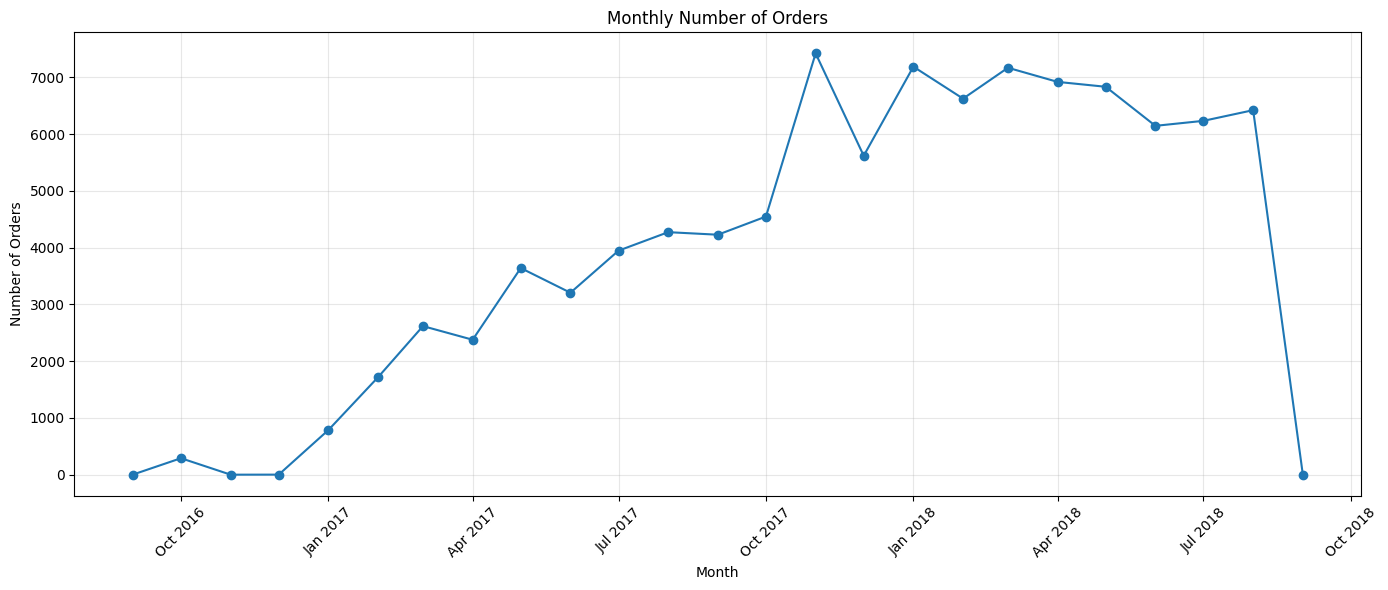

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["sales_month"],
    monthly_sales["orders"],
    marker="o"
)

plt.title("Monthly Number of Orders")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

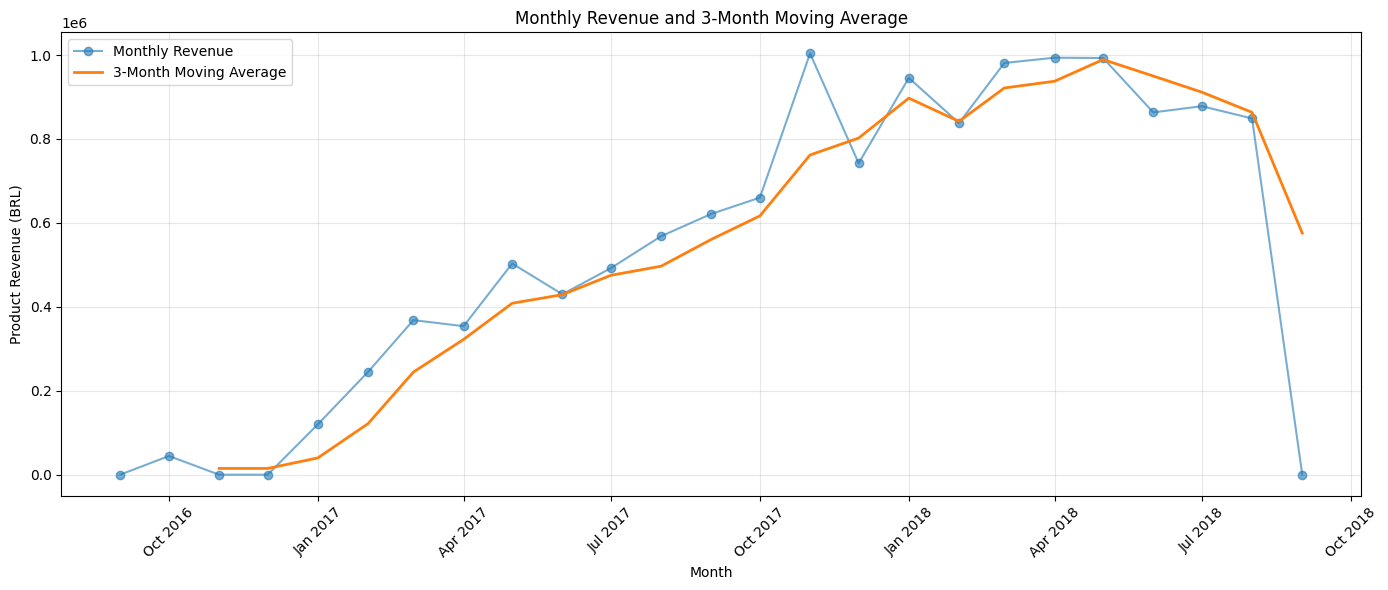

In [14]:
monthly_sales["revenue_3_month_avg"] = (
    monthly_sales["monthly_revenue"]
    .rolling(window=3, min_periods=3)
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["sales_month"],
    monthly_sales["monthly_revenue"],
    marker="o",
    alpha=0.6,
    label="Monthly Revenue"
)

plt.plot(
    monthly_sales["sales_month"],
    monthly_sales["revenue_3_month_avg"],
    linewidth=2,
    label="3-Month Moving Average"
)

plt.title("Monthly Revenue and 3-Month Moving Average")
plt.xlabel("Month")
plt.ylabel("Product Revenue (BRL)")
plt.xticks(rotation=45)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
print("Earliest purchase date:")
print(sales_data["order_purchase_timestamp"].min())

print("\nLatest purchase date:")
print(sales_data["order_purchase_timestamp"].max())

print("\nFirst and last month details:")
display(monthly_sales.head(5))
display(monthly_sales.tail(5))

Earliest purchase date:
2016-09-04 21:15:19

Latest purchase date:
2018-09-03 09:06:57

First and last month details:


,sales_month,monthly_revenue,orders,items_sold,revenue_3_month_avg
0,2016-09-01,207.86,2.0,5.0,NaN
1,2016-10-01,44507.30,290.0,342.0,NaN
2,2016-11-01,0.00,0.0,0.0,14905.053333
3,2016-12-01,10.90,1.0,1.0,14839.400000
4,2017-01-01,120098.27,787.0,953.0,40036.390000


,sales_month,monthly_revenue,orders,items_sold,revenue_3_month_avg
20,2018-05-01,992871.75,6833.0,7898.0,989171.930000
21,2018-06-01,863265.53,6145.0,7060.0,949910.086667
22,2018-07-01,878044.27,6233.0,7039.0,911393.850000
23,2018-08-01,848860.10,6421.0,7216.0,863389.966667
24,2018-09-01,145.00,1.0,1.0,575683.123333


In [16]:
# Copy the monthly sales dataset
forecast_data = monthly_sales.copy()

# Exclude the partial first and last months
forecast_data = forecast_data[
    (forecast_data["sales_month"] > "2016-09-01") &
    (forecast_data["sales_month"] < "2018-09-01")
].copy()

# Sort by month and reset the index
forecast_data = forecast_data.sort_values("sales_month").reset_index(drop=True)

# Keep the main forecasting variables
forecast_data = forecast_data[
    ["sales_month", "monthly_revenue", "orders", "items_sold"]
]

display(forecast_data.head())
display(forecast_data.tail())

print("Number of months:", len(forecast_data))
print("Date range:", forecast_data["sales_month"].min(), "to",
      forecast_data["sales_month"].max())

,sales_month,monthly_revenue,orders,items_sold
0,2016-10-01,44507.30,290.0,342.0
1,2016-11-01,0.00,0.0,0.0
2,2016-12-01,10.90,1.0,1.0
3,2017-01-01,120098.27,787.0,953.0
4,2017-02-01,244959.35,1718.0,1936.0


,sales_month,monthly_revenue,orders,items_sold
18,2018-04-01,993592.98,6919.0,7957.0
19,2018-05-01,992871.75,6833.0,7898.0
20,2018-06-01,863265.53,6145.0,7060.0
21,2018-07-01,878044.27,6233.0,7039.0
22,2018-08-01,848860.10,6421.0,7216.0


Number of months: 23
Date range: 2016-10-01 00:00:00 to 2018-08-01 00:00:00


In [17]:
display(
    forecast_data.loc[
        forecast_data["monthly_revenue"] == 0
    ]
)

,sales_month,monthly_revenue,orders,items_sold
1,2016-11-01,0.0,0.0,0.0


In [18]:
# Use the first 17 months for training and last 6 for testing
train = forecast_data.iloc[:-6].copy()
test = forecast_data.iloc[-6:].copy()

print("Training period:",
      train["sales_month"].min(), "to", train["sales_month"].max())

print("Testing period:",
      test["sales_month"].min(), "to", test["sales_month"].max())

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training period: 2016-10-01 00:00:00 to 2018-02-01 00:00:00
Testing period: 2018-03-01 00:00:00 to 2018-08-01 00:00:00
Training observations: 17
Testing observations: 6


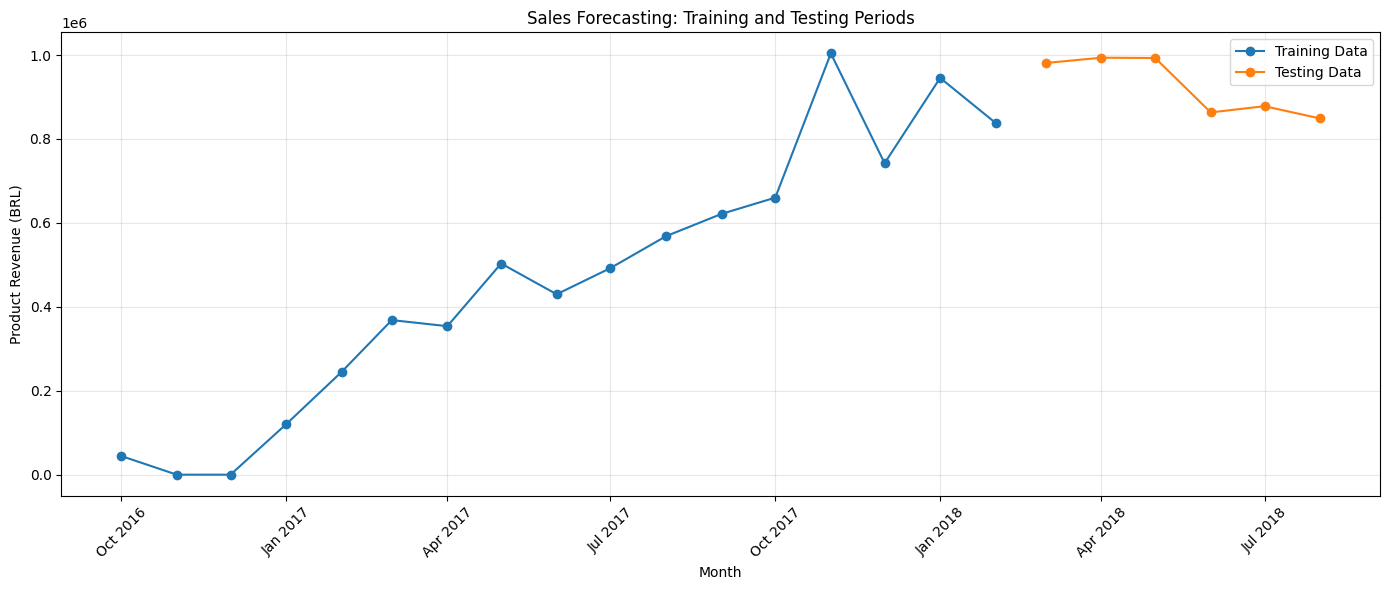

In [19]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(14, 6))

plt.plot(
    train["sales_month"],
    train["monthly_revenue"],
    marker="o",
    label="Training Data"
)

plt.plot(
    test["sales_month"],
    test["monthly_revenue"],
    marker="o",
    label="Testing Data"
)

plt.title("Sales Forecasting: Training and Testing Periods")
plt.xlabel("Month")
plt.ylabel("Product Revenue (BRL)")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
display(test[["sales_month", "monthly_revenue"]])

print("Minimum test revenue:", test["monthly_revenue"].min())
print("Maximum test revenue:", test["monthly_revenue"].max())

,sales_month,monthly_revenue
17,2018-03-01,981051.06
18,2018-04-01,993592.98
19,2018-05-01,992871.75
20,2018-06-01,863265.53
21,2018-07-01,878044.27
22,2018-08-01,848860.10


Minimum test revenue: 848860.1
Maximum test revenue: 993592.98


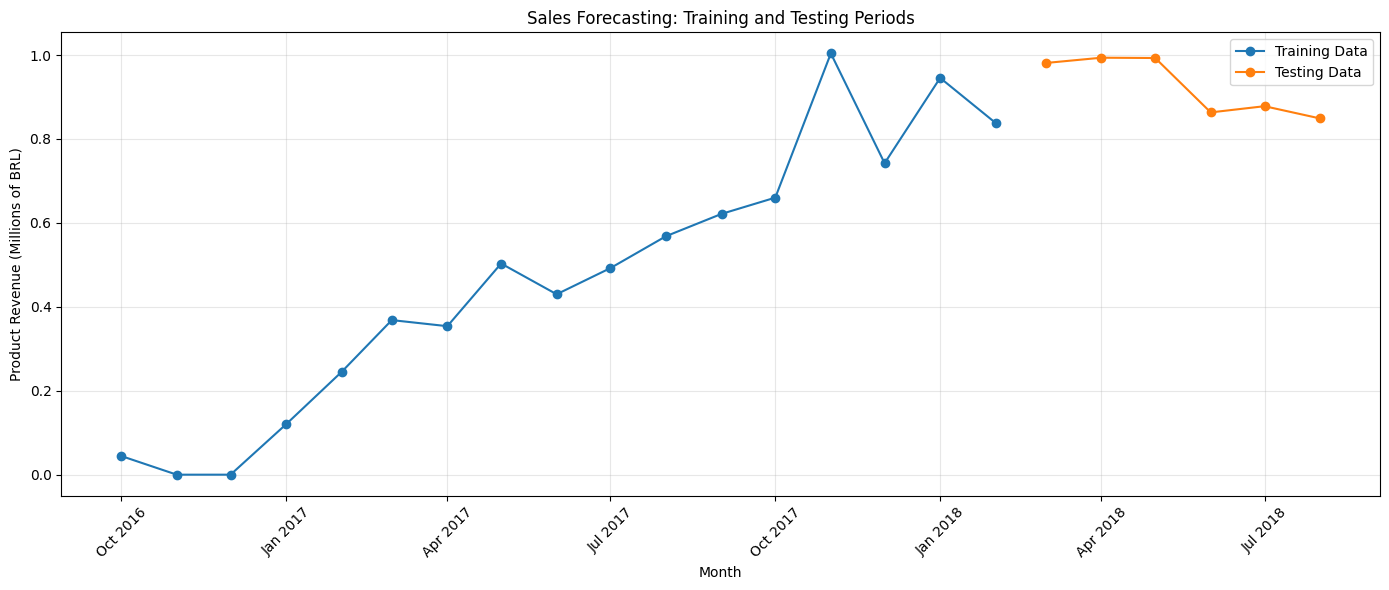

In [21]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(14, 6))

plt.plot(
    train["sales_month"],
    train["monthly_revenue"] / 1_000_000,
    marker="o",
    label="Training Data"
)

plt.plot(
    test["sales_month"],
    test["monthly_revenue"] / 1_000_000,
    marker="o",
    label="Testing Data"
)

plt.title("Sales Forecasting: Training and Testing Periods")
plt.xlabel("Month")
plt.ylabel("Product Revenue (Millions of BRL)")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
# Calculate average revenue from training data
baseline_value = train["monthly_revenue"].mean()

# Predict revenue for each test month
test["baseline_forecast"] = baseline_value

print("Average training revenue:", round(baseline_value, 2))

display(
    test[["sales_month", "monthly_revenue", "baseline_forecast"]]
)

Average training revenue: 466844.83


,sales_month,monthly_revenue,baseline_forecast
17,2018-03-01,981051.06,466844.834706
18,2018-04-01,993592.98,466844.834706
19,2018-05-01,992871.75,466844.834706
20,2018-06-01,863265.53,466844.834706
21,2018-07-01,878044.27,466844.834706
22,2018-08-01,848860.10,466844.834706


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    test["monthly_revenue"],
    test["baseline_forecast"]
)

rmse = np.sqrt(
    mean_squared_error(
        test["monthly_revenue"],
        test["baseline_forecast"]
    )
)

print("Baseline MAE:", round(mae, 2))
print("Baseline RMSE:", round(rmse, 2))

Baseline MAE: 459436.11
Baseline RMSE: 463814.97


In [24]:
from sklearn.linear_model import LinearRegression

# Create a numerical time index
train["month_number"] = np.arange(len(train))
test["month_number"] = np.arange(len(train), len(train) + len(test))

# Prepare features and target
X_train = train[["month_number"]]
y_train = train["monthly_revenue"]

X_test = test[["month_number"]]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (17, 1)
Testing shape: (6, 1)


In [25]:
# Train the model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Forecast test-period revenue
test["linear_forecast"] = linear_model.predict(X_test)

display(
    test[["sales_month", "monthly_revenue", "linear_forecast"]].round(2)
)

,sales_month,monthly_revenue,linear_forecast
17,2018-03-01,981051.06,1011150.59
18,2018-04-01,993592.98,1071629.01
19,2018-05-01,992871.75,1132107.43
20,2018-06-01,863265.53,1192585.84
21,2018-07-01,878044.27,1253064.26
22,2018-08-01,848860.10,1313542.68


In [26]:
linear_mae = mean_absolute_error(
    test["monthly_revenue"],
    test["linear_forecast"]
)

linear_rmse = np.sqrt(
    mean_squared_error(
        test["monthly_revenue"],
        test["linear_forecast"]
    )
)

print("Linear Regression MAE:", round(linear_mae, 2))
print("Linear Regression RMSE:", round(linear_rmse, 2))

Linear Regression MAE: 236065.69
Linear Regression RMSE: 286182.91


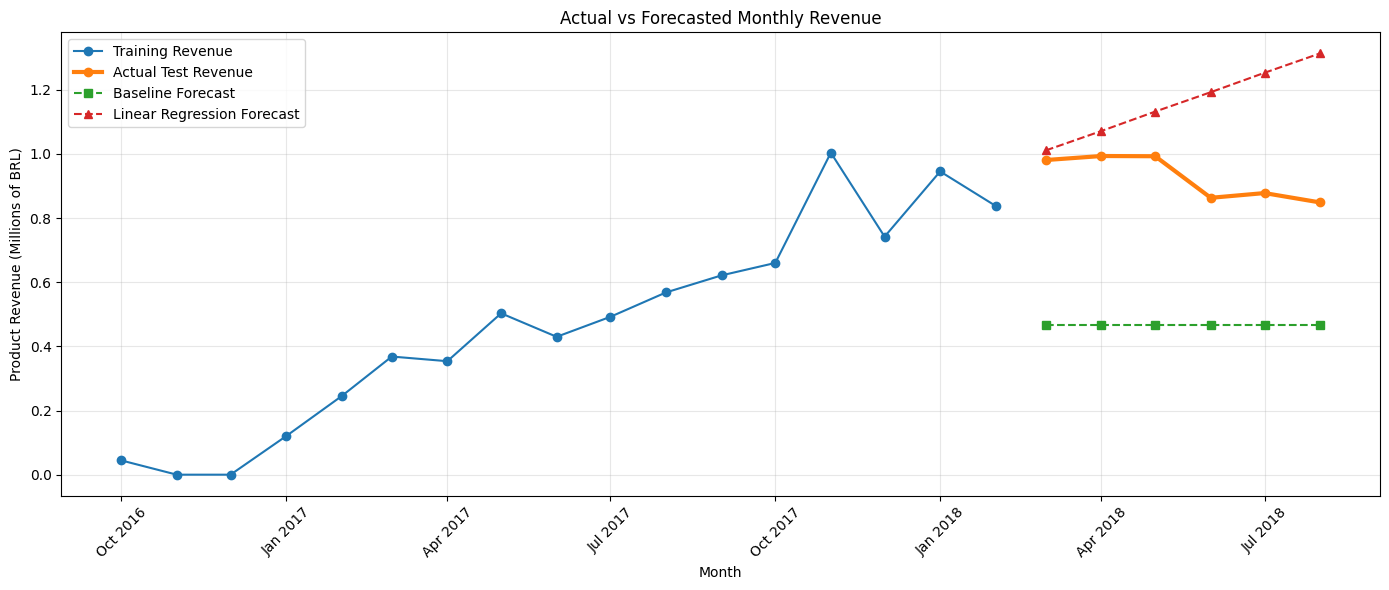

In [27]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(14, 6))

plt.plot(
    train["sales_month"],
    train["monthly_revenue"] / 1_000_000,
    marker="o",
    label="Training Revenue"
)

plt.plot(
    test["sales_month"],
    test["monthly_revenue"] / 1_000_000,
    marker="o",
    linewidth=3,
    label="Actual Test Revenue"
)

plt.plot(
    test["sales_month"],
    test["baseline_forecast"] / 1_000_000,
    marker="s",
    linestyle="--",
    label="Baseline Forecast"
)

plt.plot(
    test["sales_month"],
    test["linear_forecast"] / 1_000_000,
    marker="^",
    linestyle="--",
    label="Linear Regression Forecast"
)

plt.title("Actual vs Forecasted Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Product Revenue (Millions of BRL)")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression"],
    "MAE": [mae, linear_mae],
    "RMSE": [rmse, linear_rmse]
})

display(model_comparison.round(2))

,Model,MAE,RMSE
0,Baseline,459436.11,463814.97
1,Linear Regression,236065.69,286182.91


In [29]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [30]:
# Fit the model using training data only
es_model = ExponentialSmoothing(
    train["monthly_revenue"],
    trend=None,
    seasonal=None,
    initialization_method="estimated"
).fit()

# Forecast the next six months
test["es_forecast"] = es_model.forecast(len(test))

display(
    test[[
        "sales_month",
        "monthly_revenue",
        "es_forecast"
    ]].round(2)
)

,sales_month,monthly_revenue,es_forecast
17,2018-03-01,981051.06,853777.35
18,2018-04-01,993592.98,853777.35
19,2018-05-01,992871.75,853777.35
20,2018-06-01,863265.53,853777.35
21,2018-07-01,878044.27,853777.35
22,2018-08-01,848860.10,853777.35


In [31]:
es_mae = mean_absolute_error(
    test["monthly_revenue"],
    test["es_forecast"]
)

es_rmse = np.sqrt(
    mean_squared_error(
        test["monthly_revenue"],
        test["es_forecast"]
    )
)

print("Exponential Smoothing MAE:", round(es_mae, 2))
print("Exponential Smoothing RMSE:", round(es_rmse, 2))

Exponential Smoothing MAE: 74142.68
Exponential Smoothing RMSE: 96434.21


In [32]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Exponential Smoothing"
    ],
    "MAE": [
        mae,
        linear_mae,
        es_mae
    ],
    "RMSE": [
        rmse,
        linear_rmse,
        es_rmse
    ]
}).sort_values("MAE").reset_index(drop=True)

display(model_comparison.round(2))

,Model,MAE,RMSE
0,Exponential Smoothing,74142.68,96434.21
1,Linear Regression,236065.69,286182.91
2,Baseline,459436.11,463814.97


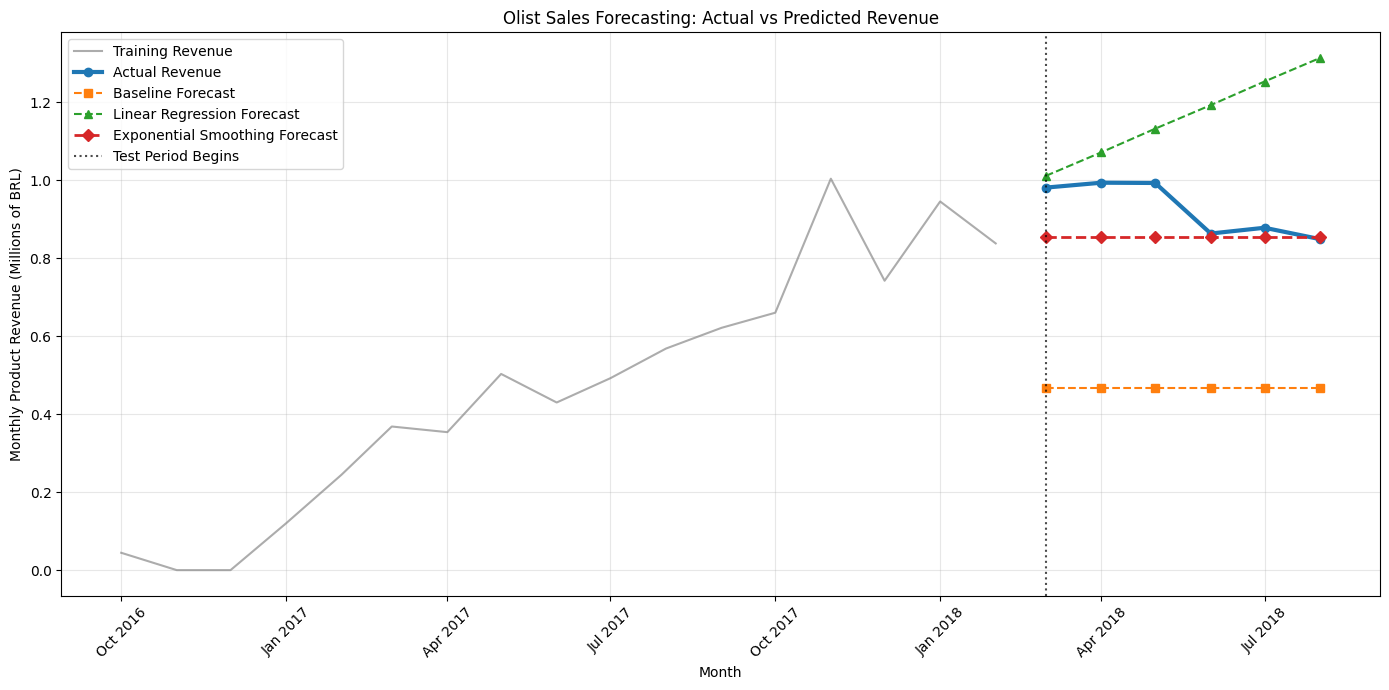

In [33]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(14, 7))

plt.plot(
    train["sales_month"],
    train["monthly_revenue"] / 1_000_000,
    color="gray",
    alpha=0.65,
    label="Training Revenue"
)

plt.plot(
    test["sales_month"],
    test["monthly_revenue"] / 1_000_000,
    marker="o",
    linewidth=3,
    label="Actual Revenue"
)

plt.plot(
    test["sales_month"],
    test["baseline_forecast"] / 1_000_000,
    marker="s",
    linestyle="--",
    label="Baseline Forecast"
)

plt.plot(
    test["sales_month"],
    test["linear_forecast"] / 1_000_000,
    marker="^",
    linestyle="--",
    label="Linear Regression Forecast"
)

plt.plot(
    test["sales_month"],
    test["es_forecast"] / 1_000_000,
    marker="D",
    linestyle="--",
    linewidth=2,
    label="Exponential Smoothing Forecast"
)

plt.axvline(
    test["sales_month"].min(),
    color="black",
    linestyle=":",
    alpha=0.7,
    label="Test Period Begins"
)

plt.title("Olist Sales Forecasting: Actual vs Predicted Revenue")
plt.xlabel("Month")
plt.ylabel("Monthly Product Revenue (Millions of BRL)")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
from pathlib import Path

# Set the output folder path
analysis_path = Path(
    r"C:\Users\LATO\Documents\Sales Analysis\Analysis Tables"
)

# Save model comparison
model_comparison.to_csv(
    analysis_path / "forecast_model_comparison.csv",
    index=False
)

# Save actual and predicted test-period revenue
forecast_results = test[
    [
        "sales_month",
        "monthly_revenue",
        "baseline_forecast",
        "linear_forecast",
        "es_forecast"
    ]
].copy()

forecast_results.to_csv(
    analysis_path / "sales_forecast_results.csv",
    index=False
)

print("Forecasting outputs saved successfully.")
print("Saved to:", analysis_path)

Forecasting outputs saved successfully.
Saved to: C:\Users\LATO\Documents\Sales Analysis\Analysis Tables


In [35]:
# Display results as tables
print("Table 1: Forecast Model Comparison")
display(model_comparison.round(2))

Table 1: Forecast Model Comparison


,Model,MAE,RMSE
0,Exponential Smoothing,74142.68,96434.21
1,Linear Regression,236065.69,286182.91
2,Baseline,459436.11,463814.97


Results Interpretation: Sales Forecasting
The table compares actual monthly revenue with predictions from three forecasting models for March–August 2018.

1. Actual Revenue: Revenue reached its highest value in April 2018 at BRL 993,592.98. It then generally declined, reaching BRL 848,860.10 in August 2018.

2. Baseline Forecast: The model predicts the same revenue of approximately BRL 466,844.83 for every month. It substantially underestimates actual revenue because it uses the average revenue from the training period.

3. Linear Regression: The model predicts continuously increasing revenue, from BRL 1,011,150.59 in March to BRL 1,313,542.68 in August. However, actual revenue declined after May, so the model overestimates revenue in the later months.

4. Exponential Smoothing: The model predicts a constant monthly revenue of approximately BRL 853,777.35. Its predictions are relatively close to actual revenue, particularly in June, July, and August.
Overall Conclusion
Exponential Smoothing performed best among the three models, achieving the lowest MAE of BRL 74,142.68 and RMSE of BRL 96,434.21. It captured the recent revenue level more accurately than the baseline and Linear Regression models during the test period.

However, because simple Exponential Smoothing produces a constant forecast here, it does not capture future trends. The results should be treated as an initial forecasting experiment because the dataset is limited and the evaluation covers only six months.